# NB05 — Week 7: Bearing Health Index + Reliability KPIs
FFT/envelope features → Isolation Forest (fit on healthy head) → Kalman smoothing.
Verified on synthetic run-to-failure; point WINDOWS_SOURCE at IMS data on the workstation.
Conversion targets: `aip_signal/health_index.py`, `aip_data/kpi.py`.

In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.signal import hilbert
from sklearn.ensemble import IsolationForest

DATA_DIR = Path("../../data")
rng = np.random.default_rng(11)

## 1. Vibration windows (synthetic run-to-failure with growing impulsive fault)

In [2]:
def synthetic_run(n_windows=120, win=2048, fs=20000.0):
    t = np.arange(win) / fs
    out = []
    for i in range(n_windows):
        x = 0.5 * np.sin(2 * np.pi * 157 * t) + rng.normal(0, 0.1, win)
        if i > n_windows * 0.6:
            sev = (i - n_windows * 0.6) / (n_windows * 0.4)
            imp = rng.random(win) < 0.002 * (1 + 5 * sev)
            x = x + imp * rng.normal(0, 3.0 * sev, win)
        out.append(x)
    return np.array(out), fs


windows, fs = synthetic_run()

## 2. Window features: RMS, kurtosis, crest, envelope RMS, log FFT band energies

In [3]:
def window_features(x, n_bands=8):
    x = x - x.mean()
    rms = np.sqrt(np.mean(x ** 2))
    kurt = np.mean((x / (x.std() + 1e-12)) ** 4)
    crest = np.max(np.abs(x)) / (rms + 1e-12)
    env = np.abs(hilbert(x))
    env_rms = np.sqrt(np.mean((env - env.mean()) ** 2))
    spec = np.abs(np.fft.rfft(x)) ** 2
    bands = np.log10(np.array([b.sum() for b in np.array_split(spec[1:], n_bands)]) + 1e-12)
    return np.concatenate([[rms, kurt, crest, env_rms], bands])


feats = np.vstack([window_features(w) for w in windows])
print("feature matrix:", feats.shape)

feature matrix: (120, 12)


## 3. Health index: IF on healthy head → baseline shift → 1-D Kalman smoothing

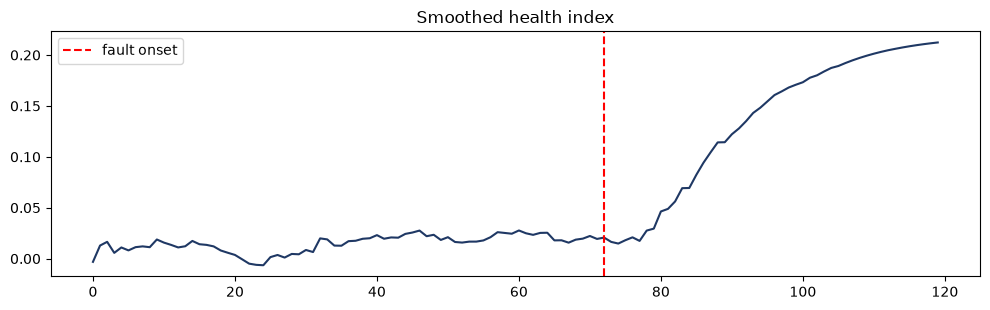

In [4]:
def kalman_smooth(z, q=1e-4, r=1e-2):
    x_hat, p, out = z[0], 1.0, np.empty_like(z, dtype=float)
    for i, m in enumerate(z):
        p += q
        k = p / (p + r)
        x_hat += k * (m - x_hat)
        p *= (1 - k)
        out[i] = x_hat
    return out


n_healthy = int(len(feats) * 0.3)
forest = IsolationForest(n_estimators=200, random_state=42).fit(feats[:n_healthy])
raw = -forest.score_samples(feats)
hi = kalman_smooth(raw - np.median(raw[:n_healthy]))

healthy, failing = hi[: len(hi) // 2], hi[int(len(hi) * 0.85):]
assert failing.mean() > healthy.mean() + 3 * healthy.std()
plt.figure(figsize=(10, 3.2))
plt.plot(hi, color="#1F3864")
plt.axvline(len(hi) * 0.6, ls="--", c="r", label="fault onset")
plt.title("Smoothed health index"); plt.legend(); plt.tight_layout()
plt.savefig(DATA_DIR / "interim/nb05_health_index.png", dpi=110)
plt.show()

## 4. Reliability KPIs — MTBF / MTTR / availability (hand-checkable scenario)

In [5]:
ts = lambda h: datetime(2026, 1, 1, h)
events = pl.DataFrame({"machine_id": ["M1"] * 5,
                       "event": ["run", "failure", "repair_done", "failure", "repair_done"],
                       "timestamp": [ts(0), ts(4), ts(6), ts(14), ts(15)]}).sort("timestamp")
fails = events.filter(pl.col("event") == "failure")
reps = events.filter(pl.col("event") == "repair_done").rename({"timestamp": "repair_ts"})
paired = fails.join_asof(reps.select("machine_id", "repair_ts"), left_on="timestamp",
                         right_on="repair_ts", by="machine_id", strategy="forward")
paired = paired.with_columns(((pl.col("repair_ts") - pl.col("timestamp"))
                              .dt.total_minutes() / 60).alias("repair_h"))
span_h = (events["timestamp"].max() - events["timestamp"].min()).total_seconds() / 3600
mttr = paired["repair_h"].mean()
mtbf = (span_h - paired["repair_h"].sum()) / len(paired)
avail = mtbf / (mtbf + mttr)
print(f"MTBF={mtbf:.1f}h  MTTR={mttr:.1f}h  availability={avail:.3f}")
assert abs(mtbf - 6) < 1e-6 and abs(mttr - 1.5) < 1e-6
print("NB05 complete.")

MTBF=6.0h  MTTR=1.5h  availability=0.800
NB05 complete.


C:\Users\sumedh_laptop\AppData\Local\Temp\ipykernel_6948\2541043350.py:7: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  paired = fails.join_asof(reps.select("machine_id", "repair_ts"), left_on="timestamp",
